## Detekcija lažnih transakcija kreditnim karticama
*Dataset: Credit Card Fraud Detection (Kaggle)*

Uvoz biblioteka

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    roc_auc_score, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_curve, auc
)
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA

Učitavanje podataka

In [2]:
df = pd.read_csv("dataset_creditcards.csv")
df = df.drop("Time", axis=1) # uklanjamo kolonu "Time" jer nije relevantna za klasifikaciju
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Broj redova i kolona:", df.shape)
print("\nNazivi kolona:")
print(df.columns.tolist())

print(df.info())
print("\nNedostajuće vrednosti po kolonama:")
print(df.isnull().sum()) # nema nedostajućih vrednosti

Broj redova i kolona: (284807, 30)

Nazivi kolona:
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 30 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   V1      284807 non-null  float64
 1   V2      284807 non-null  float64
 2   V3      284807 non-null  float64
 3   V4      284807 non-null  float64
 4   V5      284807 non-null  float64
 5   V6      284807 non-null  float64
 6   V7      284807 non-null  float64
 7   V8      284807 non-null  float64
 8   V9      284807 non-null  float64
 9   V10     284807 non-null  float64
 10  V11     284807 non-null  float64
 11  V12     284807 non-null  float64
 12  V13     284807 non-null  float64
 13  V14     284807 non-null  float64
 14  V15     284807 non

Raspodela klasa

Class
0    284315
1       492
Name: count, dtype: int64

Procentualna raspodela:
Class
0    99.83
1     0.17
Name: proportion, dtype: float64


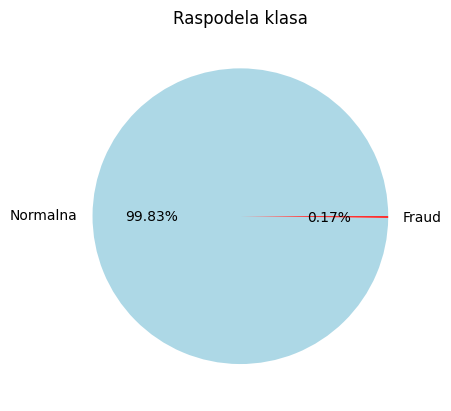

In [4]:
print(df["Class"].value_counts())
print("\nProcentualna raspodela:")
print(df["Class"].value_counts(normalize=True).mul(100).round(2))

df["Class"].value_counts().plot(kind="pie", labels=["Normalna", "Fraud"], 
    autopct="%1.2f%%", colors=["lightblue", "red"])
plt.title("Raspodela klasa")
plt.ylabel("")
plt.show()

In [5]:
print(df["Amount"].describe().round(2))


count    284807.00
mean         88.35
std         250.12
min           0.00
25%           5.60
50%          22.00
75%          77.16
max       25691.16
Name: Amount, dtype: float64


Podela na X i y 

In [6]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Dimenzije X:", X.shape)
print("Dimenzije y:", y.shape)

Dimenzije X: (284807, 29)
Dimenzije y: (284807,)


Podela na obučavajući i testirajući skup

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train fraud broj:", y_train.sum())
print("y_test fraud broj:", y_test.sum())

X_train: (227845, 29)
X_test: (56962, 29)
y_train fraud broj: 394
y_test fraud broj: 98


Skaliranje 

In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (227845, 29)
X_test_scaled shape: (56962, 29)


Linearni klasifikator

In [9]:

svm_linear = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=10000,
    C = 0.01
)

svm_linear.fit(X_train_scaled, y_train)

print("Linearni SVM klasifikator je istreniran.")

Linearni SVM klasifikator je istreniran.


Predikcija i evaluacija istreniranog linearnog SVM klasifikatora na test skupu

In [10]:
y_pred_linear = svm_linear.predict(X_test_scaled)
y_score_linear = svm_linear.decision_function(X_test_scaled)

/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [11]:
print("Konfuziona matrica:")
print(confusion_matrix(y_test, y_pred_linear))


print("\nIzveštaj o klasifikaciji za Linearni SVM klasifikator:")
print(f"{'Klasa':<15} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 45)

for klasa in [0, 1]:
    p = precision_score(y_test, y_pred_linear, pos_label=klasa)
    r = recall_score(y_test, y_pred_linear, pos_label=klasa)
    f = f1_score(y_test, y_pred_linear, pos_label=klasa)
    naziv = "Normalna (0)" if klasa == 0 else "Fraud (1)"
    print(f"{naziv:<15} {p:>10.4f} {r:>10.4f} {f:>10.4f}")

print("-" * 45)
print(f"{'Accuracy':<15} {accuracy_score(y_test, y_pred_linear):>10.4f}")


roc_auc_linear = roc_auc_score(y_test, y_score_linear)

Konfuziona matrica:
[[55676  1188]
 [    9    89]]

Izveštaj o klasifikaciji za Linearni SVM klasifikator:
Klasa            Precision     Recall         F1
---------------------------------------------
Normalna (0)        0.9998     0.9791     0.9894
Fraud (1)           0.0697     0.9082     0.1295
---------------------------------------------
Accuracy            0.9790


Prikaz konfuzione matrice

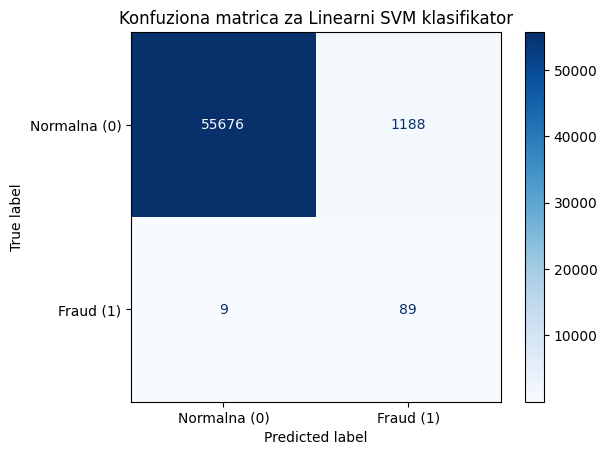

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_linear, 
    display_labels=["Normalna (0)", "Fraud (1)"],
    cmap=plt.cm.Blues
)
plt.title("Konfuziona matrica za Linearni SVM klasifikator")
plt.show()

Redukcija skupa za obučavanje zbog računske složenosti RBF SVM-a

In [13]:
X_train_small, _, y_train_small, _ = train_test_split(
    X_train_scaled, y_train,
    train_size=50000,
    random_state=42,
    stratify=y_train
)

print("X_train_small:", X_train_small.shape)

X_train_small: (50000, 29)


RBF SVM model

In [14]:
svm_rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale",
    class_weight="balanced",
    random_state=42
)

svm_rbf.fit(X_train_small, y_train_small)

print("RBF SVM model je istreniran.")

RBF SVM model je istreniran.


Predikcija i evaluacija RBF modela

In [15]:
y_pred_rbf = svm_rbf.predict(X_test_scaled)
y_score_rbf = svm_rbf.decision_function(X_test_scaled)

In [16]:
print("Konfuziona matrica:")
print(confusion_matrix(y_test, y_pred_rbf))

print("\nIzveštaj o klasifikaciji za RBF SVM klasifikator:")
print(f"{'Klasa':<15} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 45)

for klasa in [0, 1]:
    p = precision_score(y_test, y_pred_rbf, pos_label=klasa)
    r = recall_score(y_test, y_pred_rbf, pos_label=klasa)
    f = f1_score(y_test, y_pred_rbf, pos_label=klasa)
    naziv = "Normalna (0)" if klasa == 0 else "Fraud (1)"
    print(f"{naziv:<15} {p:>10.4f} {r:>10.4f} {f:>10.4f}")

print("-" * 45)
print(f"{'Accuracy':<15} {accuracy_score(y_test, y_pred_rbf):>10.4f}")

roc_auc_rbf = roc_auc_score(y_test, y_score_rbf)

Konfuziona matrica:
[[56800    64]
 [   50    48]]

Izveštaj o klasifikaciji za RBF SVM klasifikator:
Klasa            Precision     Recall         F1
---------------------------------------------
Normalna (0)        0.9991     0.9989     0.9990
Fraud (1)           0.4286     0.4898     0.4571
---------------------------------------------
Accuracy            0.9980


Prikaz konfuzione matrice za RBF SVM

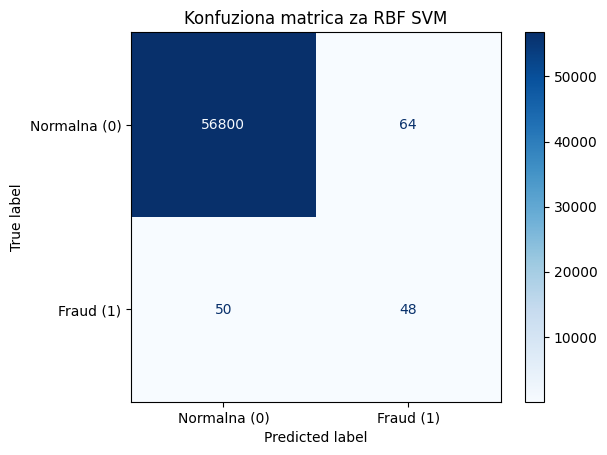

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rbf,
    display_labels=["Normalna (0)", "Fraud (1)"],
    cmap=plt.cm.Blues
)

plt.title("Konfuziona matrica za RBF SVM")
plt.show()

SMOTE (sintetički generisanje novih primera frauda dok ne izjednači broj primera obe klase)

In [18]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Pre SMOTE:")
print(y_train.value_counts())

print("\nPosle SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Pre SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

Posle SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


SVM na kreiranom SMOTE modelu

In [19]:
svm_smote = LinearSVC(
    random_state=42,
    max_iter=10000,
    C= 0.01
)

svm_smote.fit(X_train_smote, y_train_smote)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.01
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo ran

In [20]:
y_pred_smote = svm_smote.predict(X_test_scaled)
y_score_smote = svm_smote.decision_function(X_test_scaled)

/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/utils/extmath.py:227: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Evaluacija SMOTE modela

In [21]:
print("Konfuziona matrica:")
print(confusion_matrix(y_test, y_pred_smote))

print("\nIzveštaj o klasifikaciji za SVM + SMOTE klasifikator:")
print(f"{'Klasa':<15} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 45)

for klasa in [0, 1]:
    p = precision_score(y_test, y_pred_smote, pos_label=klasa)
    r = recall_score(y_test, y_pred_smote, pos_label=klasa)
    f = f1_score(y_test, y_pred_smote, pos_label=klasa)
    naziv = "Normalna (0)" if klasa == 0 else "Fraud (1)"
    print(f"{naziv:<15} {p:>10.4f} {r:>10.4f} {f:>10.4f}")

print("-" * 45)
print(f"{'Accuracy':<15} {accuracy_score(y_test, y_pred_smote):>10.4f}")

roc_auc_smote = roc_auc_score(y_test, y_score_smote)

Konfuziona matrica:
[[55576  1288]
 [    9    89]]

Izveštaj o klasifikaciji za SVM + SMOTE klasifikator:
Klasa            Precision     Recall         F1
---------------------------------------------
Normalna (0)        0.9998     0.9773     0.9885
Fraud (1)           0.0646     0.9082     0.1207
---------------------------------------------
Accuracy            0.9772


Prikaz konfuzion matrice za SMOTE model

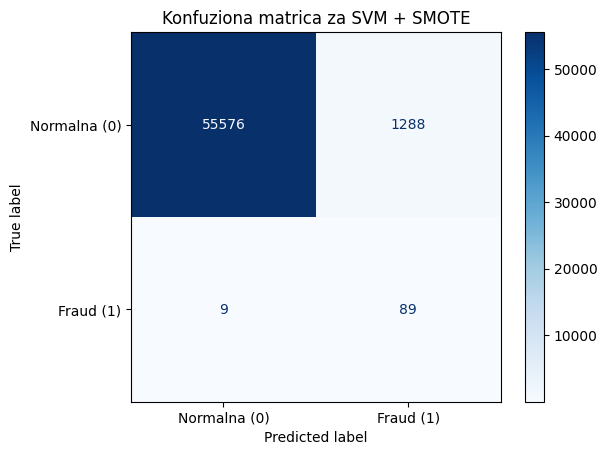

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_smote,
    display_labels=["Normalna (0)", "Fraud (1)"],
    cmap=plt.cm.Blues
)
plt.title("Konfuziona matrica za SVM + SMOTE")
plt.show()

ROC kriva za sva tri modela

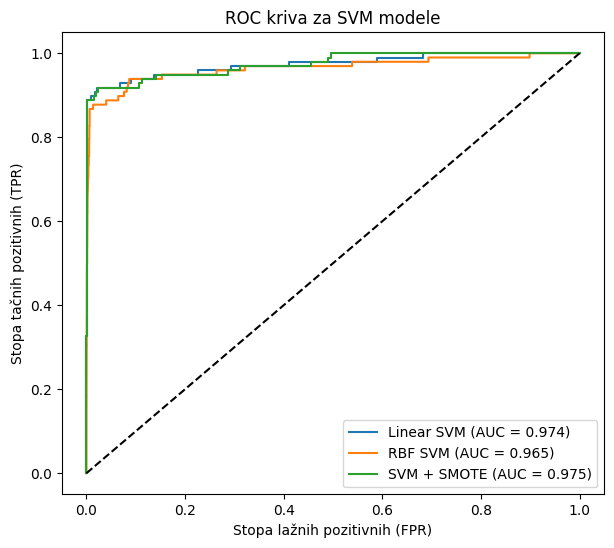

In [23]:
fpr_linear, tpr_linear, _ = roc_curve(y_test, y_score_linear)
roc_auc_linear = auc(fpr_linear, tpr_linear)

fpr_rbf, tpr_rbf, _ = roc_curve(y_test, y_score_rbf)
roc_auc_rbf = auc(fpr_rbf, tpr_rbf)

fpr_smote, tpr_smote, _ = roc_curve(y_test, y_score_smote)
roc_auc_smote = auc(fpr_smote, tpr_smote)

plt.figure(figsize=(7,6))

plt.plot(fpr_linear, tpr_linear, label=f"Linear SVM (AUC = {roc_auc_linear:.3f})")
plt.plot(fpr_rbf, tpr_rbf, label=f"RBF SVM (AUC = {roc_auc_rbf:.3f})")
plt.plot(fpr_smote, tpr_smote, label=f"SVM + SMOTE (AUC = {roc_auc_smote:.3f})")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("Stopa lažnih pozitivnih (FPR)")
plt.ylabel("Stopa tačnih pozitivnih (TPR)")
plt.title("ROC kriva za SVM modele")
plt.legend()
plt.show()

Tabelarno poređenje ova tri modela

In [24]:
results = pd.DataFrame({
    "Model": ["Linearni SVM", "RBF SVM", "SVM + SMOTE"],
    "Precision (fraud)": [
        precision_score(y_test, y_pred_linear),
        precision_score(y_test, y_pred_rbf),
        precision_score(y_test, y_pred_smote)
    ],
    "Recall (fraud)": [
        recall_score(y_test, y_pred_linear),
        recall_score(y_test, y_pred_rbf),
        recall_score(y_test, y_pred_smote)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_linear),
        f1_score(y_test, y_pred_rbf),
        f1_score(y_test, y_pred_smote)
    ],
    "ROC-AUC": [
        roc_auc_linear,
        roc_auc_rbf,
        roc_auc_smote
    ]
})

results

,Model,Precision (fraud),Recall (fraud),F1-score,ROC-AUC
0,Linearni SVM,0.069695,0.908163,0.129455,0.973798
1,RBF SVM,0.428571,0.489796,0.457143,0.964634
2,SVM + SMOTE,0.064633,0.908163,0.120678,0.974705


PCA vizuelizacija

/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/sklearn/decomposition/_base.py:152: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


Objašnjena varijansa: [0.06874643 0.05284118]


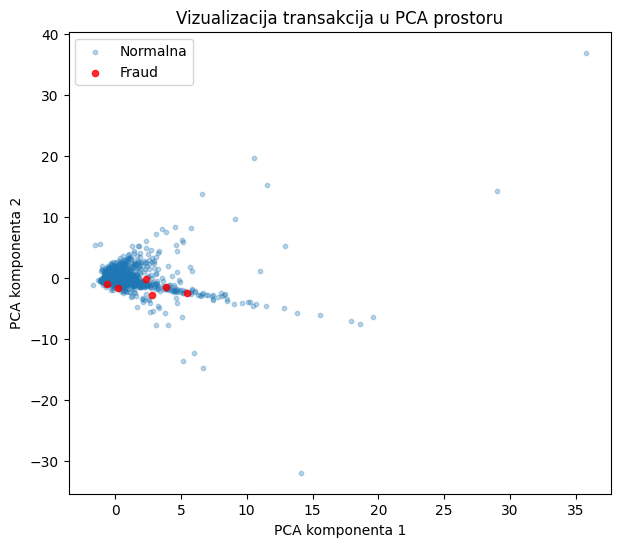

In [25]:
df_sample = df.sample(n=5000, random_state=42)

X_sample = df_sample.drop("Class", axis=1)
y_sample = df_sample["Class"]

scaler_pca = StandardScaler()
X_sample_scaled = scaler_pca.fit_transform(X_sample)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sample_scaled)

print("Objašnjena varijansa:", pca.explained_variance_ratio_)

plt.figure(figsize=(7,6))

plt.scatter(
    X_pca[y_sample == 0, 0],
    X_pca[y_sample == 0, 1],
    alpha=0.3,
    label="Normalna",
    s=10
)

plt.scatter(
    X_pca[y_sample == 1, 0],
    X_pca[y_sample == 1, 1],
    alpha=0.8,
    label="Fraud",
    color="red",
    s=20
)

plt.xlabel("PCA komponenta 1")
plt.ylabel("PCA komponenta 2")
plt.title("Vizualizacija transakcija u PCA prostoru")
plt.legend()
plt.show()

Bayes

In [26]:
from sklearn.naive_bayes import GaussianNB

fraud_prior  = y_train.mean()
normal_prior = 1 - fraud_prior

gnb = GaussianNB(priors=[normal_prior, fraud_prior])
gnb.fit(X_train_scaled, y_train)
p_fraud = gnb.predict_proba(X_test_scaled)[:, 1]

cost_ratios = [1, 2, 5, 10, 20, 50, 100, 200, 500]
rows = []
for ratio in cost_ratios:
    threshold  = 1.0 / (1.0 + ratio)
    y_pred_tmp = (p_fraud >= threshold).astype(int)
    cm         = confusion_matrix(y_test, y_pred_tmp)
    tn, fp, fn, tp = cm.ravel()
    rows.append({
        "C_FN/C_FP": ratio,
        "Prag":      round(threshold, 4),
        "Precision": round(precision_score(y_test, y_pred_tmp, zero_division=0), 4),
        "Recall":    round(recall_score(y_test, y_pred_tmp), 4),
        "F1":        round(f1_score(y_test, y_pred_tmp, zero_division=0), 4),
        "TP": tp, "FP": fp, "FN": fn
    })

df_nb = pd.DataFrame(rows)
print(df_nb.to_string(index=False))

# Optimum po F1
best = df_nb.loc[df_nb["F1"].idxmax()]
print(f"\nOptimalan cost ratio: {best['C_FN/C_FP']}  →  prag = {best['Prag']}")
print(f"Precision={best['Precision']}, Recall={best['Recall']}, F1={best['F1']}")

 C_FN/C_FP   Prag  Precision  Recall     F1  TP   FP  FN
         1 0.5000     0.0587  0.8469 0.1099  83 1330  15
         2 0.3333     0.0580  0.8469 0.1086  83 1348  15
         5 0.1667     0.0569  0.8469 0.1066  83 1376  15
        10 0.0909     0.0565  0.8571 0.1060  84 1403  14
        20 0.0476     0.0554  0.8571 0.1041  84 1432  14
        50 0.0196     0.0547  0.8673 0.1030  85 1468  13
       100 0.0099     0.0545  0.8776 0.1026  86 1493  12
       200 0.0050     0.0538  0.8776 0.1014  86 1512  12
       500 0.0020     0.0524  0.8776 0.0989  86 1556  12

Optimalan cost ratio: 1.0  →  prag = 0.5
Precision=0.0587, Recall=0.8469, F1=0.1099


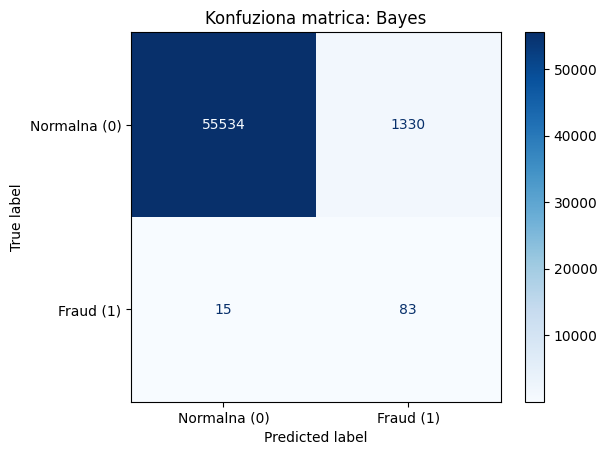

ROC-AUC: 0.9629


In [27]:
best_threshold = best["Prag"]
y_pred_nb      = (p_fraud >= best_threshold).astype(int)
y_score_nb     = p_fraud
roc_auc_nb     = roc_auc_score(y_test, y_score_nb)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_nb,
    display_labels=["Normalna (0)", "Fraud (1)"],
    cmap=plt.cm.Blues
)
plt.title(f"Konfuziona matrica: Bayes")
plt.show()

print(f"ROC-AUC: {roc_auc_nb:.4f}")

Knn metoda

In [28]:
from sklearn.neighbors import KNeighborsClassifier

k_values  = [5, 11, 21, 51]
k_results = []

for k in k_values:
    knn_temp = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",  
        metric="euclidean",
        n_jobs=-1
    )
    knn_temp.fit(X_train_small, y_train_small)
    y_pred_temp = knn_temp.predict(X_test_scaled)
    f1 = f1_score(y_test, y_pred_temp, zero_division=0)
    recall = recall_score(y_test, y_pred_temp)
    precision = precision_score(y_test, y_pred_temp, zero_division=0)
    k_results.append({
        "k": k,
        "Precision (fraud)": round(precision, 4),
        "Recall (fraud)": round(recall, 4),
        "F1 (fraud)": round(f1, 4)
    })
    print(f"  k={k:>3} → Precision={precision:.4f}, Recall={recall:.4f}, F1={f1:.4f}")

print("\nRezultati pretrage k:")
print(pd.DataFrame(k_results).to_string(index=False))

  k=  5 → Precision=0.8444, Recall=0.7755, F1=0.8085
  k= 11 → Precision=0.8222, Recall=0.7551, F1=0.7872
  k= 21 → Precision=0.8132, Recall=0.7551, F1=0.7831
  k= 51 → Precision=0.8095, Recall=0.6939, F1=0.7473

Rezultati pretrage k:
 k  Precision (fraud)  Recall (fraud)  F1 (fraud)
 5             0.8444          0.7755      0.8085
11             0.8222          0.7551      0.7872
21             0.8132          0.7551      0.7831
51             0.8095          0.6939      0.7473


In [29]:
best_k_row = max(k_results, key=lambda x: x["F1 (fraud)"])
best_k = best_k_row["k"]
print(f"Optimalno k = {best_k} (F1 fraud = {best_k_row['F1 (fraud)']})")

knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights="distance",
    metric="euclidean",
    n_jobs=-1
)
knn.fit(X_train_small, y_train_small)

Optimalno k = 5 (F1 fraud = 0.8085)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",-1


Konfuziona matrica (KNN):
[[56850    14]
 [   22    76]]

Izveštaj o klasifikaciji za KNN:
Klasa            Precision     Recall         F1
---------------------------------------------
Normalna (0)        0.9996     0.9998     0.9997
Fraud (1)           0.8444     0.7755     0.8085

ROC-AUC: 0.9182


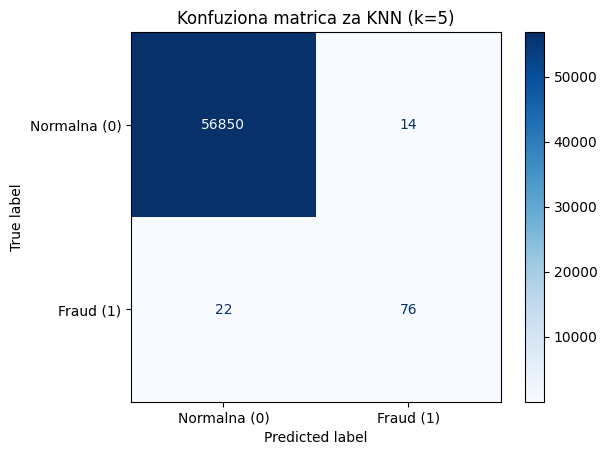

In [30]:
y_pred_knn = knn.predict(X_test_scaled)

y_score_knn = knn.predict_proba(X_test_scaled)[:, 1]

print("Konfuziona matrica (KNN):")
print(confusion_matrix(y_test, y_pred_knn))

print("\nIzveštaj o klasifikaciji za KNN:")
print(f"{'Klasa':<15} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 45)
for klasa in [0, 1]:
    p = precision_score(y_test, y_pred_knn, pos_label=klasa, zero_division=0)
    r = recall_score(y_test, y_pred_knn, pos_label=klasa)
    f = f1_score(y_test, y_pred_knn, pos_label=klasa, zero_division=0)
    naziv = "Normalna (0)" if klasa == 0 else "Fraud (1)"
    print(f"{naziv:<15} {p:>10.4f} {r:>10.4f} {f:>10.4f}")

roc_auc_knn = roc_auc_score(y_test, y_score_knn)
print(f"\nROC-AUC: {roc_auc_knn:.4f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn,
    display_labels=["Normalna (0)", "Fraud (1)"],
    cmap=plt.cm.Blues
)
plt.title(f"Konfuziona matrica za KNN (k={best_k})")
plt.show()

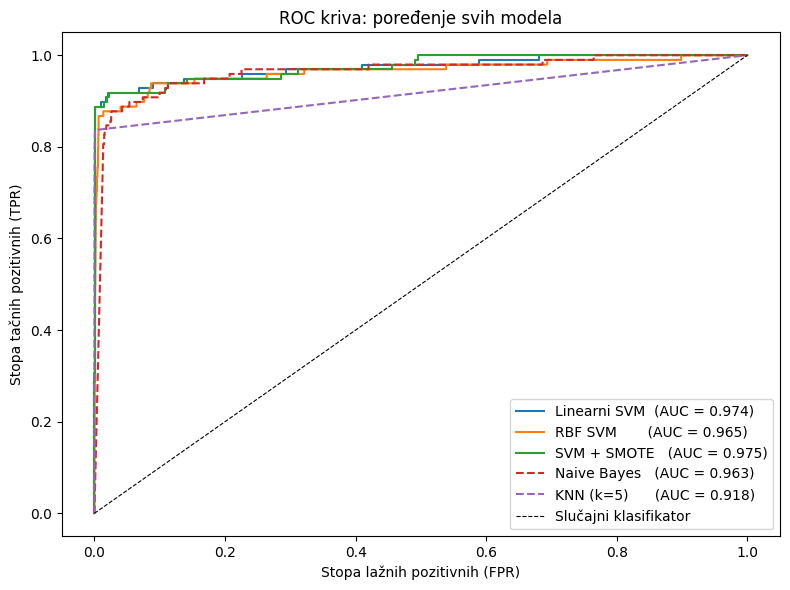

In [32]:
fpr_nb,  tpr_nb,  _ = roc_curve(y_test, y_score_nb)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_score_knn)

plt.figure(figsize=(8, 6))
plt.plot(fpr_linear, tpr_linear, label=f"Linearni SVM  (AUC = {roc_auc_linear:.3f})")
plt.plot(fpr_rbf,    tpr_rbf,    label=f"RBF SVM       (AUC = {roc_auc_rbf:.3f})")
plt.plot(fpr_smote,  tpr_smote,  label=f"SVM + SMOTE   (AUC = {roc_auc_smote:.3f})")
plt.plot(fpr_nb,     tpr_nb,     label=f"Naive Bayes   (AUC = {roc_auc_nb:.3f})",  linestyle="--")
plt.plot(fpr_knn,    tpr_knn,    label=f"KNN (k={best_k})      (AUC = {roc_auc_knn:.3f})", linestyle="--")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Slučajni klasifikator")
plt.xlabel("Stopa lažnih pozitivnih (FPR)")
plt.ylabel("Stopa tačnih pozitivnih (TPR)")
plt.title("ROC kriva: poređenje svih modela")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()